# Gerchberg-Saxton ponderado de fase fija contra slmsuite

**Pregunta:** ¿Iguala el Gerchberg-Saxton ponderado de fase fija de DinHot al estado del arte, los algoritmos ponderados de slmsuite ejecutados sobre el mismo objetivo y la misma grilla de 1024 trampas, en eficiencia, uniformidad y número de iteraciones para llegar?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** notebook 02 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

En arreglos de miles de sitios, como los 6.100 átomos en unas 12.000 pinzas de trabajos recientes (Manetsch et al. 2025), la uniformidad del algoritmo ponderado es el límite del experimento, y el campo se asentó en un algoritmo práctico: Gerchberg-Saxton ponderado que congela la fase del plano focal después de una docena de iteraciones (Kim et al. 2019). DinHot lo implementa como M07. La afirmación que se prueba no es que DinHot supere a alguien: es que su implementación es un miembro fiel del estado del arte, de modo que todo notebook posterior pueda usarla como línea base. Ejecutarás M06 y M07 en las 1024 trampas del caso C03, ejecutarás slmsuite 0.5.0, una biblioteca de código abierto con los mismos algoritmos, con sus pesos de Leonardo y de Kim sobre las mismas trampas, la misma grilla FFT, el mismo haz gaussiano y la misma fase de inicio, evaluarás todos con las mismas métricas y leerás la diferencia en la figura y en la tabla. Una comparación compara los códigos solo cuando todo lo demás es igual, así que cada corrida de una semilla, en DinHot y en slmsuite, parte de una misma fase del SLM.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 slmsuite==0.5.0
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, los módulos del pipeline por su ruta y la implementación de referencia fijada
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
import slmsuite
from slmsuite.holography.algorithms import SpotHologram

slmsuite.configure_logging(None)  # sin registro de consola dentro de las salidas

for name in ("numpy", "matplotlib", "slmsuite"):
    print(name, md.version(name))


def trap_numbers(phi, setup, traps):
    """Eficiencia, uniformidad y dispersión relativa (por ciento) de un holograma, leídas en la grilla FFT."""
    v = forward.trap_fields_from_fft(forward.fft_focal_field(phi, setup), setup, traps)
    i = metrics.trap_intensities(v)
    return metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)


def first_below(curve, percent):
    """La primera iteración (contando desde 1) cuya dispersión queda bajo ``percent``, o None."""
    return next((k + 1 for k, row in enumerate(curve) if row[2] < percent), None)

numpy 2.4.6
matplotlib 3.11.2
slmsuite 0.5.0


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot, para el caso; slmsuite es una biblioteca de código abierto para holografía con SLM, licencia MIT, fijada en 0.5.0 (https://pypi.org/project/slmsuite/).
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros; la implementación de referencia se usa como biblioteca bajo su propia licencia.
- Archivo leído: `data/examples/cases.json`, caso C03, una red de 32 por 32 con 1024 trampas sobre el SLM de 256 por 256 píxeles, con la semilla del caso y la siguiente.

In [2]:
# caso C03: 1024 trampas, 32 x 32, en el SLM de 256 x 256 píxeles; ambas implementaciones reciben este arreglo y este
# haz
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C03_large_array"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
seeds = [rec["seed"], rec["seed"] + 1]
# una fase de inicio por semilla, uniforme en el SLM, entregada a todos los métodos del notebook
starts = {seed: np.random.default_rng(seed).uniform(-np.pi, np.pi, (setup.n_pix, setup.n_pix)) for seed in seeds}
iy, ix = forward.trap_bins(setup, traps)
spots = np.vstack([ix, iy])
print(f"{len(traps)} trampas, bin focal {geometry.focal_bin_m(setup) * 1e6:.3f} um")
print(f"{rec['budget']['iterations']} iteraciones del presupuesto")
print(f"trampas por píxel del SLM: {len(traps) / setup.n_pix**2 * 100:.2f} % de los píxeles")

1024 trampas, bin focal 0.498 um
30 iteraciones del presupuesto
trampas por píxel del SLM: 1.56 % de los píxeles


## Método

La actualización ponderada del notebook 02 es $w_m \leftarrow w_m \langle r\rangle/r_m$ con $r_m = |V_m|/a_m$, y el pedido es $c_m = w_m a_m e^{i\psi_m}$ con $\psi_m = \arg V_m$ (Di Leonardo et al. 2007, https://doi.org/10.1364/OE.15.001913). La variante de fase fija (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178; M07 en el producto) sigue al campo durante las primeras $N$ iteraciones, $\psi_i = \arg V_m^{i}$, y luego lo congela, $\psi_i = \psi_N$ para $i \geq N$, de modo que las iteraciones posteriores solo ajustan amplitudes. Kim informa una eficiencia de modulación de 91,2 por ciento para 1500 focos con $N = 12$; el producto toma $N = 12$ como valor por defecto. Con 1024 trampas sobre un SLM de 256 por 256 hay 64 píxeles por trampa, de modo que es un holograma apretado, que es el régimen donde el algoritmo importa. Las celdas siguientes ejecutan los dos métodos ponderados del producto desde las fases de inicio de la celda de datos (una fase aleatoria uniforme del SLM por semilla, entregada como `init`) y preguntan cuándo ayuda congelar.

La primera celda ejecuta Gerchberg-Saxton ponderado (M06) y la variante de fase fija (M07) durante las 30 iteraciones del caso, con dos semillas cada una. Informa el promedio de la eficiencia, la uniformidad y la dispersión finales sobre las semillas y la primera iteración en que la dispersión de cada semilla baja de 1 por ciento.

In [3]:
# DinHot: GS ponderado (M06) y WGS de fase fija (M07, la fase se congela tras 12 iteraciones), dos semillas cada uno
budget = Budget(rec["budget"]["iterations"])
product = {"M06": [], "M07": []}
for seed in seeds:
    product["M06"].append(m06_gsw.run(setup, target, budget=budget, rng=Rng(seed), init=starts[seed]))
    product["M07"].append(m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(seed), init=starts[seed]))
for name, results in product.items():
    curve = [[(h["efficiency"], h["uniformity"], h["rel_std"]) for h in res.history] for res in results]
    final = np.mean([c[-1] for c in curve], axis=0)
    print(f"{name}: e = {final[0]:.4f}, u = {final[1]:.4f}, sigma = {final[2]:.3f} %")
    print(f"     primera iteración bajo 1 por ciento, por semilla: {[first_below(c, 1.0) for c in curve]}")

M06: e = 0.8057, u = 0.9465, sigma = 1.429 %
     primera iteración bajo 1 por ciento, por semilla: [None, None]
M07: e = 0.7934, u = 0.9952, sigma = 0.183 %
     primera iteración bajo 1 por ciento, por semilla: [15, 15]


La iteración de congelamiento es un parámetro, y el valor por defecto del producto es el publicado. La celda ejecuta M07 con $N$ igual a 6, 12 y 20 con la primera semilla e imprime la dispersión en las iteraciones 12, 20 y 30, para ver qué compra el valor por defecto en este arreglo.

In [4]:
# cuándo congelar: n_fix = 6, 12 y 20 iteraciones antes de fijar la fase focal
frozen = {}
for n_fix in (6, 12, 20):
    res = m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(seeds[0]), init=starts[seeds[0]], n_fix=n_fix)
    frozen[n_fix] = [h["rel_std"] for h in res.history]
    at = [frozen[n_fix][k - 1] for k in (12, 20, 30)]
    print(f"n_fix = {n_fix:2d}: sigma en la iteración 12, 20, 30 = " + ", ".join(f"{x:.3f}" for x in at) + " %")

n_fix =  6: sigma en la iteración 12, 20, 30 = 1.432, 1.962, 2.106 %
n_fix = 12: sigma en la iteración 12, 20, 30 = 3.390, 0.250, 0.180 %
n_fix = 20: sigma en la iteración 12, 20, 30 = 3.390, 1.755, 0.156 %


## Estado del arte

slmsuite es una biblioteca de Python de código abierto para calcular hologramas en SLM. Su `SpotHologram` recibe una lista de puntos en las coordenadas de píxel del plano de Fourier con relleno (la base knm), la amplitud del haz sobre el SLM y la forma de la grilla de cálculo, y su `optimize` trae por nombre los métodos ponderados de la literatura: `WGS-Leonardo` implementa la actualización de Di Leonardo et al. con una potencia $p$ sobre la razón de amplitudes, y `WGS-Kim` fija la fase después de `fix_phase_iteration` iteraciones. Las entradas de abajo son las del producto: los mismos 1024 bins de la misma grilla de 512 por 512, el mismo haz gaussiano normalizado, una fase de 256 por 256, 30 iteraciones y, fijada con `reset_phase(custom_phase=...)`, la misma fase de inicio que la corrida de DinHot de esa semilla. Una opción no queda en su valor por defecto: slmsuite eleva la razón de amplitudes de la actualización de pesos a una potencia `feedback_exponent` de 0,8 por defecto, mientras que Di Leonardo et al. y Kim et al. escriben la razón misma, potencia 1, que es la que usan M06 y M07 de DinHot. Las corridas de abajo usan la potencia 1, para que los dos códigos calculen el mismo algoritmo, y una corrida extra de WGS-Kim con el valor por defecto 0,8 de slmsuite muestra lo que cambia esa sola opción. Ambas implementaciones se leen con la misma función: la fase que devuelve slmsuite se transforma con el modelo directo de DinHot y las trampas se leen en sus bins.

La celda construye un `SpotHologram` por corrida, fija su fase de inicio, ejecuta 30 iteraciones de `WGS-Leonardo` y de `WGS-Kim` con potencia 1 para cada una de las dos semillas, y de `WGS-Kim` con la potencia 0,8 por defecto para las mismas semillas, y guarda con un callback la fase que usó cada iteración, para poder dibujar la dispersión contra la iteración. Luego evalúa cada fase guardada con las métricas del producto. El registro de slmsuite se apaga al importar para que la celda imprima solo lo que imprime el notebook.

In [5]:
# slmsuite sobre el mismo objetivo: los mismos puntos, grilla, haz y fase de inicio,
# con la potencia de peso 1 de los artículos (y 0.8, el valor por defecto de slmsuite)
beam = geometry.input_amplitude(setup)
size = setup.n_fft
runs = {"WGS-Leonardo": ("WGS-Leonardo", 1.0), "WGS-Kim": ("WGS-Kim", 1.0), "WGS-Kim potencia 0.8": ("WGS-Kim", 0.8)}
reference = {name: [] for name in runs}
final_phase = {}
for name, (method, power) in runs.items():
    for seed in seeds:
        holo = SpotHologram(shape=(size, size), spot_vectors=spots, basis="knm", spot_amp=np.ones(len(traps)),
                            cameraslm=None, slm_shape=(setup.n_pix, setup.n_pix), amp=beam)
        holo.reset_phase(custom_phase=starts[seed])
        phases = []
        holo.optimize(method=method, maxiter=30, verbose=False, fix_phase_iteration=12, feedback_exponent=power,
                      callback=lambda h: phases.append(np.array(h.phase, dtype=float)))
        phases.append(np.array(holo.get_phase(), dtype=float))
        final_phase[(name, seed)] = phases[-1]
        reference[name].append([trap_numbers(p, setup, traps) for p in phases[1:]])
print({m: len(v) for m, v in reference.items()}, "corridas de cada método")


{'WGS-Leonardo': 2, 'WGS-Kim': 2, 'WGS-Kim potencia 0.8': 2} corridas de cada método


La celda siguiente pone las cinco corridas en una tabla: la eficiencia, la uniformidad y la dispersión finales promediadas sobre las dos semillas y la primera iteración en que la dispersión de cada semilla queda bajo 1 por ciento.

In [6]:
# los números finales de cada corrida en una tabla, leídos con las métricas propias de DinHot
rows = {}
for name, results in product.items():
    rows[name] = [[(h["efficiency"], h["uniformity"], h["rel_std"]) for h in res.history] for res in results]
for method, curves in reference.items():
    rows["slmsuite " + method] = curves
for name, curves in rows.items():
    final = np.mean([c[-1] for c in curves], axis=0)
    need = [first_below(c, 1.0) for c in curves]
    per_seed = ", ".join(f"{c[-1][2]:.3f}" for c in curves)
    print(f"{name:30s} e = {final[0]:.4f}  u = {final[1]:.4f}  sigma = {final[2]:6.3f} %")
    print(f"{'':30s} sigma por semilla: {per_seed} %; primera iteración bajo 1 por ciento, por semilla: {need}")
# el mismo inicio, el mismo algoritmo: la mayor diferencia de la dispersión final entre semillas,
# M07 frente a WGS-Kim y M06 frente a WGS-Leonardo
for ours, theirs in (("M07", "slmsuite WGS-Kim"), ("M06", "slmsuite WGS-Leonardo")):
    gap = max(abs(a[-1][2] - b[-1][2]) for a, b in zip(rows[ours], rows[theirs]))
    print(f"{ours} frente a {theirs}: mayor diferencia de la dispersión final = {gap:.5f} puntos porcentuales")

M06                            e = 0.8057  u = 0.9465  sigma =  1.429 %
                               sigma por semilla: 1.423, 1.436 %; primera iteración bajo 1 por ciento, por semilla: [None, None]
M07                            e = 0.7934  u = 0.9952  sigma =  0.183 %
                               sigma por semilla: 0.180, 0.187 %; primera iteración bajo 1 por ciento, por semilla: [15, 15]
slmsuite WGS-Leonardo          e = 0.8057  u = 0.9465  sigma =  1.429 %
                               sigma por semilla: 1.423, 1.436 %; primera iteración bajo 1 por ciento, por semilla: [None, None]
slmsuite WGS-Kim               e = 0.7934  u = 0.9952  sigma =  0.183 %
                               sigma por semilla: 0.180, 0.187 %; primera iteración bajo 1 por ciento, por semilla: [15, 15]
slmsuite WGS-Kim potencia 0.8  e = 0.7938  u = 0.9947  sigma =  0.218 %
                               sigma por semilla: 0.233, 0.203 %; primera iteración bajo 1 por ciento, por semilla: [17, 17]
M07 fre

La primera figura grafica la dispersión relativa contra la iteración para la primera semilla de cada una de las cinco corridas, en un eje logarítmico: los métodos de DinHot como líneas anchas y pálidas, los de slmsuite como líneas delgadas segmentadas, para que una curva dibujada sobre otra siga visible. La línea vertical punteada marca la iteración 12, donde los dos métodos de fase fija congelan la fase focal.

dispersión relativa (%) en las primeras iteraciones, primera semilla:
iteración  1: M06 38.60, M07 38.60, slmsuite WGS-Leonardo 38.60, slmsuite WGS-Kim 38.60, slmsuite WGS-Kim potencia 0.8 38.60
iteración  2: M06 31.67, M07 31.67, slmsuite WGS-Leonardo 31.67, slmsuite WGS-Kim 31.67, slmsuite WGS-Kim potencia 0.8 23.62
iteración  3: M06 20.31, M07 20.31, slmsuite WGS-Leonardo 20.31, slmsuite WGS-Kim 20.31, slmsuite WGS-Kim potencia 0.8 16.96
iteración  4: M06 15.48, M07 15.48, slmsuite WGS-Leonardo 15.48, slmsuite WGS-Kim 15.48, slmsuite WGS-Kim potencia 0.8 14.73
iteración  5: M06 11.54, M07 11.54, slmsuite WGS-Leonardo 11.54, slmsuite WGS-Kim 11.54, slmsuite WGS-Kim potencia 0.8 12.56
iteración  6: M06 8.83, M07 8.83, slmsuite WGS-Leonardo 8.83, slmsuite WGS-Kim 8.83, slmsuite WGS-Kim potencia 0.8 10.21
iteración  8: M06 6.12, M07 6.12, slmsuite WGS-Leonardo 6.12, slmsuite WGS-Kim 6.12, slmsuite WGS-Kim potencia 0.8 7.34
iteración 12: M06 3.39, M07 3.39, slmsuite WGS-Leonardo 3.39, sl

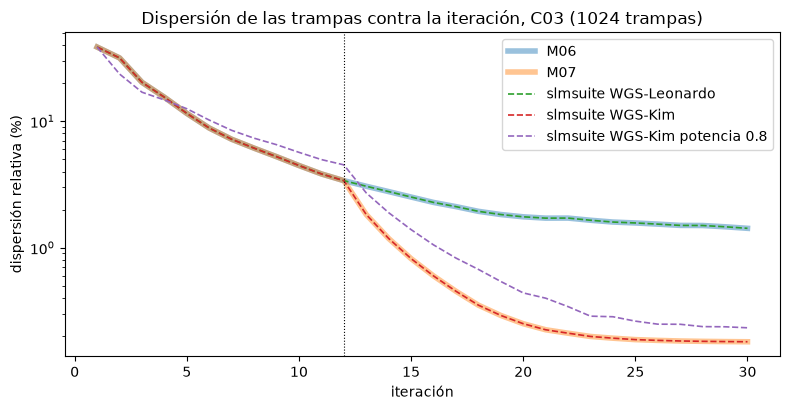

In [7]:
# la dispersión contra la iteración, primera semilla de cada método, en un eje logarítmico
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, curves in rows.items():
    style = {"lw": 1.2, "ls": "--"} if name.startswith("slmsuite") else {"lw": 4.0, "alpha": 0.45}
    ax.semilogy(np.arange(1, 31), [row[2] for row in curves[0]], label=name, **style)
print("dispersión relativa (%) en las primeras iteraciones, primera semilla:")
for k in (1, 2, 3, 4, 5, 6, 8, 12):
    print(f"iteración {k:2d}: " + ", ".join(f"{name} {curves[0][k - 1][2]:.2f}" for name, curves in rows.items()))
ax.axvline(12, color="k", ls=":", lw=0.8)
ax.set_xlabel("iteración")
ax.set_ylabel("dispersión relativa (%)")
ax.set_title("Dispersión de las trampas contra la iteración, C03 (1024 trampas)")
ax.legend()
fig.tight_layout()
plt.show()

Cada curva de DinHot queda cubierta por su contraparte de slmsuite a lo largo de toda la corrida: M06 por WGS-Leonardo, M07 por WGS-Kim, de modo que solo se ve la línea ancha y pálida alrededor de la delgada y discontinua; las iteraciones impresas coinciden en dos decimales, y las mayores diferencias de la tabla, 0,00001 y 0,00002 puntos porcentuales, dicen lo mismo sobre toda la corrida. Hasta la línea punteada las cuatro corridas con potencia 1 son la misma actualización ponderada; en la iteración 12 el par de fase fija se dobla hacia abajo de inmediato, mientras que el par sin congelar sigue lento y termina cerca de 1,4 por ciento: ese es el efecto de congelar la fase. La quinta curva, WGS-Kim con la potencia 0,8 por defecto de slmsuite, parte la misma actualización con una corrección más suave, baja más rápido en las tres primeras iteraciones (23,62 frente a 31,67 por ciento en la iteración 2, y bajo las otras en las iteraciones 2 a 4), queda sobre las otras de la iteración 5 al congelamiento (12,56 frente a 11,54 por ciento en la iteración 5, 4,52 frente a 3,39 en la 12) y termina sobre M07, en 0,218 frente a 0,183 por ciento: la sola opción por defecto mueve el resultado en cerca de un quinto, más que cualquier diferencia entre los dos códigos.

La segunda figura dibuja el histograma de las 1024 potencias de las trampas, divididas por su promedio, tras 30 iteraciones, para M07 y para WGS-Kim de slmsuite con la primera semilla, sobre un eje compartido.

M07: mínimo 0.9945, máximo 1.0041 de la media
slmsuite WGS-Kim: mínimo 0.9945, máximo 1.0041 de la media


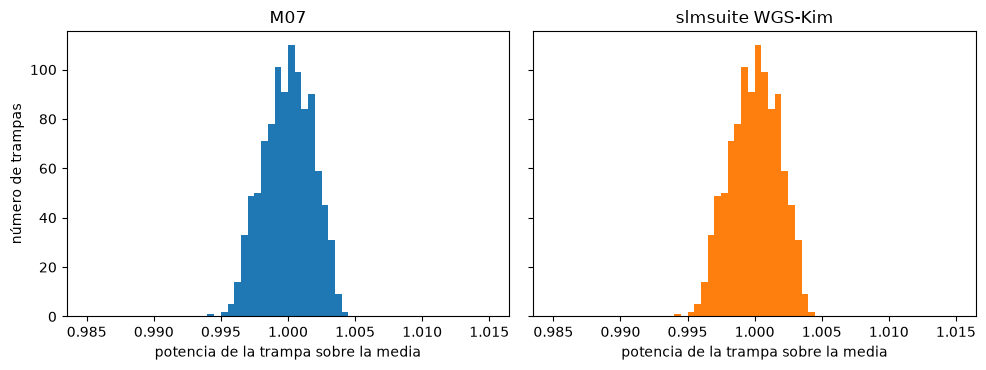

In [8]:
# la potencia de las 1024 trampas tras 30 iteraciones, M07 y WGS-Kim de slmsuite, relativa a la media, en un eje
# compartido
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True)
shown = (("M07", product["M07"][0].phi), ("slmsuite WGS-Kim", final_phase[("WGS-Kim", seeds[0])]))
edges = np.linspace(0.985, 1.015, 61)
for ax, (name, phi) in zip(axes, shown):
    i = metrics.trap_intensities(forward.trap_fields_from_fft(forward.fft_focal_field(phi, setup), setup, traps))
    ax.hist(i / i.mean(), bins=edges, color="C0" if name == "M07" else "C1")
    ax.set_title(name)
    ax.set_xlabel("potencia de la trampa sobre la media")
    print(f"{name}: mínimo {i.min() / i.mean():.4f}, máximo {i.max() / i.mean():.4f} de la media")
axes[0].set_ylabel("número de trampas")
fig.tight_layout()
plt.show()


Los dos histogramas son el mismo: la trampa más débil está en 0,9945 de la media y la más fuerte en 1,0041 en ambos, y las barras coinciden bin a bin, como deben para dos fases que concuerdan hasta el quinto dígito de la dispersión. Casi todas las trampas quedan a menos de medio por ciento de la potencia media. La figura muestra solo el estado final; cuántas iteraciones necesita cada uno está en la última columna de la tabla, 15 para ambos.

## Resultados

**Respuesta:** Sí. Desde la misma fase de inicio, en las mismas 1024 trampas de C03, la misma grilla y el mismo haz gaussiano, M07 de fase fija de DinHot y WGS-Kim de slmsuite con la potencia de peso de los artículos llegan al mismo holograma: una eficiencia de 0,7934, una uniformidad de 0,9952 y una dispersión de 0,183 por ciento en el promedio de dos semillas (0,180 y 0,187), con dispersiones finales que difieren a lo más en 0,00002 puntos porcentuales, y ambos llevan la dispersión bajo 1 por ciento en la iteración 15. M06 ponderado de DinHot y WGS-Leonardo de slmsuite concuerdan del mismo modo (1,429 por ciento, a lo más 0,00001 de diferencia) y no bajan de 1 por ciento en 30 iteraciones. Con la potencia 0,8 por defecto de slmsuite, WGS-Kim termina en 0,218 por ciento y necesita 17 iteraciones, de modo que una comparación con los valores por defecto de la biblioteca compara dos variantes del algoritmo, no dos códigos. La iteración de congelamiento importa: con $N = 12$ la dispersión es 0,180 por ciento en la iteración 30 con la primera semilla, con $N = 6$ es 2,106 por ciento, y con $N = 20$ es 0,156 por ciento. La implementación del producto es el estado del arte; el notebook no muestra que sea mejor.

## Resumen

Congelar la fase focal después de una docena de iteraciones convierte la cola lenta de Gerchberg-Saxton ponderado en una caída rápida hasta unas pocas décimas de por ciento. Corridos desde el mismo inicio, con la potencia de peso que escriben los artículos, M07 y M06 de DinHot calculan los mismos hologramas que WGS-Kim y WGS-Leonardo de slmsuite hasta el quinto dígito, de modo que M07 es la línea base del estado del arte de los notebooks siguientes tal como está; una comparación con la potencia por defecto de slmsuite, o desde inicios distintos, mide otra cosa. Lo que la comparación no cubre es la calidad de la regla de congelamiento en arreglos que no están apretados, una cámara en el lazo o un SLM que no es ideal: lo último es el tema del notebook siguiente, donde el modelo del dispositivo entra en el lazo mismo.

## Referencias

- Kim, Kim, Lee y Ahn, "Gerchberg-Saxton algorithm with phase fixing for tweezer arrays", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- Manetsch et al., "A tweezer array with 6100 highly coherent atomic qubits" (2025), https://arxiv.org/abs/2403.12021.
- slmsuite 0.5.0 (MIT), https://pypi.org/pypi/slmsuite/json y https://pypi.org/project/slmsuite/.